# Flight Price Prediction — Random Forest

## 1. Setup

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import OrdinalEncoder
import time, warnings, pickle
warnings.filterwarnings('ignore')
# from google.colab import drive
# drive.mount('/content/drive')

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# TRAIN_PATH = '/content/drive/MyDrive/ML_Flight_price_prediction/train.csv'
# TEST_PATH  = '/content/drive/MyDrive/ML_Flight_price_prediction/test.csv'
TRAIN_PATH = 'Regression_Dataset/train.csv'      
TEST_PATH  = 'Regression_Dataset/test.csv'        

STOPS_MAP = {"zero": 0, "one": 1, "two_or_more": 2}
TIME_ORD  = {"Early_Morning": 0, "Morning": 1, "Afternoon": 2,
             "Evening": 3, "Night": 4, "Late_Night": 5}
CLASS_MAP = {"Economy": 0, "Business": 1}

def evaluate(y_true, y_pred, label=""):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    if label:
        print(f"  {label:<50}  R²={r2:.4f}  RMSE={rmse:.2f}  MAE={mae:.2f}")
    return {"R2": round(r2,4), "RMSE": round(rmse,2), "MAE": round(mae,2)}


## 2. Feature Engineering

Centralised in one function so it applies identically to train and test.

In [32]:
def engineer_features(df):
    df = df.copy()

    #  Ordinal mappings (preserve natural order) ─
    df["stops_num"]     = df["stops"].map(STOPS_MAP).fillna(0)
    df["departure_num"] = df["departure_time"].map(TIME_ORD).fillna(0)
    df["arrival_num"]   = df["arrival_time"].map(TIME_ORD).fillna(0)
    df["class_num"]     = df["flight_class"].map(CLASS_MAP).fillna(0)

    # Route combination
    df["route"]            = df["source_city"] + "_" + df["destination_city"]

    # Numerical transforms 
    df["duration_per_stop"] = df["duration"] / (df["stops_num"] + 1)
    df["days_left_sq"]      = df["days_left"] ** 2
    df["log_duration"]      = np.log1p(df["duration"])
    df["log_days_left"]     = np.log1p(df["days_left"])
    df["inv_days"]          = 1.0 / (df["days_left"] + 1)    # inverse: last-minute surge
    df["log_dur_days"]      = df["log_duration"] * df["log_days_left"]  # joint log signal

    # Class interactions
    df["business_long"]     = df["class_num"] * df["duration"]  # Business × duration
    df["stops_class"]       = df["stops_num"] * df["class_num"]
    df["days_class"]        = df["days_left"] * df["class_num"]
    df["class_inv_days"]    = df["class_num"] * df["inv_days"]  # Business urgency premium
    df["nonstop_business"]  = ((df["stops_num"] == 0) & (df["class_num"] == 1)).astype(int)

    # Categorical interaction strings (for target encoding)
    df["carrier"]            = df["flight"].str.split().str[0]
    df["airline_class"]      = df["airline"]      + "_" + df["flight_class"]
    df["route_class"]        = df["route"]        + "_" + df["flight_class"]
    df["airline_stops"]      = df["airline"]      + "_" + df["stops"]
    df["airline_route"]      = df["airline"]      + "_" + df["route"]
    df["route_class_stops"]  = df["route"]        + "_" + df["flight_class"] + "_" + df["stops"]
    df["depart_arrive"]      = df["departure_time"] + "_" + df["arrival_time"]

    return df

## 3. Target Encoding — Out-of-Fold (Train) + Full-Mean (Test)

In [33]:
# OrdinalEncoder assigns arbitrary integers to categorical values. 
# Target encoding replaces each category with its mean price, 
# giving the model direct pricing signal per airline, route, class combination.

TE_COLS = [
    "airline",            # airline pricing tier
    "route",              # specific route price level
    "airline_class",      # airline × class (most informative combo)
    "route_class",        # route × class
    "airline_stops",      # airline × stop count
    "airline_route",      # airline × route (specific flight path)
    "route_class_stops",  # route × class × stops (finest granularity — top feature)
    "carrier",            # IATA carrier code
    "depart_arrive",      # time-of-day combo
]


# Fitting TE on the same rows you train on leaks label information leading to inflated validation scores. 
# OOF TE: for each training row, the mean is computed from the other folds only. 
# For the test set, we use means from the full training set.

def oof_target_encode(df, te_cols, target_col="price", n_splits=5, seed=42):
    """
    Out-of-fold target encoding for training data.
    For each row i, the encoded value = mean(target) over all rows NOT in the same fold as i.
    Returns df with target encoded columns added.
    """
    df = df.copy()
    global_mean = df[target_col].mean()
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    for col in te_cols:
        encoded = np.full(len(df), global_mean)
        for tr_idx, vl_idx in kf.split(df):
            fold_means = df.iloc[tr_idx].groupby(col)[target_col].mean()
            encoded[vl_idx] = df.iloc[vl_idx][col].map(fold_means).fillna(global_mean).values
        df[f"te_{col}"] = encoded

    return df

def apply_test_target_encode(df_test, train_df_raw, te_cols, target_col="price"):
    """
    Apply target encoding to test set using FULL training set means.
    Must use raw (pre-ordinal-encoding) train data for groupby to work correctly.
    """
    df_test = df_test.copy()
    global_mean = train_df_raw[target_col].mean()
    for col in te_cols:
        means = train_df_raw.groupby(col)[target_col].mean()
        df_test[f"te_{col}"] = df_test[col].map(means).fillna(global_mean)
    return df_test

## 4. Load & Prepare Training Data

In [34]:
#Load
df_raw = pd.read_csv(TRAIN_PATH)
print(f"Raw train shape: {df_raw.shape}")
print(f"Zero-price rows: {(df_raw['price']==0).sum()} → removed")

df = df_raw[df_raw["price"] > 0].copy().reset_index(drop=True)
print(f"Clean train shape: {df.shape}")

#  Feature engineering ─
df = engineer_features(df)

#  OOF Target Encoding ─
print("\nRunning OOF target encoding (5-fold)...")
t0 = time.time()
df = oof_target_encode(df, TE_COLS, target_col="price", n_splits=5, seed=SEED)
print(f"Done in {time.time()-t0:.1f}s")

#  Ordinal Encoding for all categoricals ─
CAT_COLS = [
    "airline", "source_city", "destination_city", "route",
    "departure_time", "arrival_time", "flight_class", "stops",
    "airline_class", "route_class", "airline_stops", "airline_route",
    "route_class_stops", "depart_arrive", "carrier"
]
oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
df[CAT_COLS] = oe.fit_transform(df[CAT_COLS])
print("OrdinalEncoder fitted.")

#  Feature list 
FEATURES = [
    # Ordinal-encoded categoricals
    "airline", "source_city", "destination_city", "route",
    "departure_time", "arrival_time", "flight_class", "stops",
    # Raw numericals
    "duration", "days_left",
    # Ordinal-mapped numericals
    "stops_num", "departure_num", "arrival_num", "class_num",
    # Numerical features
    "duration_per_stop", "days_left_sq", "log_duration", "log_days_left",
    "inv_days", "log_dur_days",
    # Class interactions
    "business_long", "stops_class", "days_class", "class_inv_days", "nonstop_business",
    # Interaction categoricals (ordinal encoded)
    "airline_class", "route_class", "airline_stops", "airline_route",
    "route_class_stops", "depart_arrive", "carrier",
    # Target-encoded features (the most powerful ones)
] + [f"te_{c}" for c in TE_COLS]

print(f"\nTotal features: {len(FEATURES)}")
print(f" of which target-encoded: {len(TE_COLS)}")

X = df[FEATURES]
y = df["price"]
print(f"\nX shape: {X.shape}   y shape: {y.shape}")

Raw train shape: (18076, 12)
Zero-price rows: 25 → removed
Clean train shape: (18051, 12)

Running OOF target encoding (5-fold)...
Done in 0.5s
OrdinalEncoder fitted.

Total features: 41
 of which target-encoded: 9

X shape: (18051, 41)   y shape: (18051,)


## 5. Validation Setup

Because OOF TE is computed on the full training set before splitting, our single-split val score is slightly optimistic. The true generalisation score is better estimated by the proper nested KFold. We use the single-split as a fast ranking tool for hyperparameter search.

In [35]:
X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.15, random_state=SEED)
print(f"Train: {X_tr.shape}  |  Val: {X_val.shape}")

# Baseline comparison: v1 config (no TE, old features)
CAT_ORIG = ["airline","source_city","destination_city","route","departure_time","arrival_time",
            "flight_class","stops","airline_class","route_class","airline_stops","airline_route"]
df_v1 = df_raw[df_raw["price"]>0].copy()
df_v1["stops_num"]    = df_v1["stops"].map(STOPS_MAP)
df_v1["departure_num"]= df_v1["departure_time"].map(TIME_ORD)
df_v1["arrival_num"]  = df_v1["arrival_time"].map(TIME_ORD)
df_v1["class_num"]    = df_v1["flight_class"].map(CLASS_MAP)
df_v1["route"]        = df_v1["source_city"]+"_"+df_v1["destination_city"]
df_v1["duration_per_stop"]=df_v1["duration"]/(df_v1["stops_num"]+1)
df_v1["days_left_sq"] = df_v1["days_left"]**2
df_v1["log_duration"] = np.log1p(df_v1["duration"])
df_v1["log_days_left"]= np.log1p(df_v1["days_left"])
df_v1["business_long"]= df_v1["class_num"]*df_v1["duration"]
df_v1["stops_class"]  = df_v1["stops_num"]*df_v1["class_num"]
df_v1["days_class"]   = df_v1["days_left"]*df_v1["class_num"]
df_v1["airline_class"]= df_v1["airline"]+"_"+df_v1["flight_class"]
df_v1["route_class"]  = df_v1["route"]+"_"+df_v1["flight_class"]
df_v1["airline_stops"]= df_v1["airline"]+"_"+df_v1["stops"]
df_v1["airline_route"]= df_v1["airline"]+"_"+df_v1["route"]
oe_v1=OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1)
df_v1[CAT_ORIG]=oe_v1.fit_transform(df_v1[CAT_ORIG])
FEAT_V1=["airline","source_city","destination_city","route","departure_time","arrival_time",
         "flight_class","stops","duration","days_left","stops_num","departure_num","arrival_num",
         "class_num","duration_per_stop","days_left_sq","log_duration","log_days_left",
         "business_long","stops_class","days_class","airline_class","route_class","airline_stops","airline_route"]
Xv1=df_v1[FEAT_V1]; yv1=df_v1["price"]
Xv1_tr,Xv1_vl,yv1_tr,yv1_vl=train_test_split(Xv1,yv1,test_size=0.15,random_state=SEED)
rf_v1=RandomForestRegressor(n_estimators=100,max_features=0.7,min_samples_leaf=3,
                            max_samples=0.8,max_depth=25,random_state=SEED,n_jobs=-1)
rf_v1.fit(Xv1_tr,yv1_tr)
evaluate(yv1_vl, np.maximum(rf_v1.predict(Xv1_vl),0))

Train: (15343, 41)  |  Val: (2708, 41)


{'R2': 0.7816, 'RMSE': np.float64(95.85), 'MAE': 42.61}

## 6. Hyperparameter Tuning (with Target Encoding features)

In [36]:
print("Hyperparameter search on v2 feature set:")
print("Fixed: OOF target encoding applied to training, full-set means for test\n")

results = []
configs = [
    # (n_estimators, max_features, min_samples_leaf, max_samples)
    (100, 0.7,  3, 0.80), 
    (200, 0.50, 2, 0.85),
    (200, 0.40, 2, 0.85),
    (200, 0.35, 2, 0.85),   # best found in search
    (200, 0.35, 2, 0.90),
    (200, 0.35, 3, 0.85),
    (200, 0.30, 2, 0.85),
    (200, 0.30, 3, 0.85),
    (300, 0.35, 2, 0.85),
    (300, 0.30, 3, 0.85),
]

for n, mf, msl, ms in configs:
    t0 = time.time()
    rf = RandomForestRegressor(n_estimators=n, max_features=mf,
                               min_samples_leaf=msl, max_samples=ms,
                               random_state=SEED, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    p = np.maximum(rf.predict(X_val), 0)
    r2 = r2_score(y_val, p)
    rmse = np.sqrt(mean_squared_error(y_val, p))
    results.append({"n_estimators":n,"max_features":mf,"min_samples_leaf":msl,
                    "max_samples":ms,"R2":round(r2,4),"RMSE":round(rmse,2)})
    print(f"  n={n:<3} mf={mf} msl={msl} ms={ms}  R²={r2:.4f}  RMSE={rmse:.1f}  "
          f"[{time.time()-t0:.1f}s]")

hp_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print("\nTop 5 configs:")
display(hp_df.head(5))

BEST_N   = int(hp_df.iloc[0].n_estimators)
BEST_MF  = hp_df.iloc[0].max_features
BEST_MSL = int(hp_df.iloc[0].min_samples_leaf)
BEST_MS  = hp_df.iloc[0].max_samples
print(f"\nBest: n={BEST_N} mf={BEST_MF} msl={BEST_MSL} ms={BEST_MS}  R²={hp_df.iloc[0].R2}")

Hyperparameter search on v2 feature set:
Fixed: OOF target encoding applied to training, full-set means for test

  n=100 mf=0.7 msl=3 ms=0.8  R²=0.7806  RMSE=96.1  [1.0s]
  n=200 mf=0.5 msl=2 ms=0.85  R²=0.7826  RMSE=95.6  [1.5s]
  n=200 mf=0.4 msl=2 ms=0.85  R²=0.7830  RMSE=95.6  [1.3s]
  n=200 mf=0.35 msl=2 ms=0.85  R²=0.7828  RMSE=95.6  [1.2s]
  n=200 mf=0.35 msl=2 ms=0.9  R²=0.7847  RMSE=95.2  [1.3s]
  n=200 mf=0.35 msl=3 ms=0.85  R²=0.7838  RMSE=95.4  [1.2s]
  n=200 mf=0.3 msl=2 ms=0.85  R²=0.7870  RMSE=94.7  [1.2s]
  n=200 mf=0.3 msl=3 ms=0.85  R²=0.7853  RMSE=95.0  [1.1s]
  n=300 mf=0.35 msl=2 ms=0.85  R²=0.7843  RMSE=95.3  [2.2s]
  n=300 mf=0.3 msl=3 ms=0.85  R²=0.7858  RMSE=94.9  [1.9s]

Top 5 configs:


,n_estimators,max_features,min_samples_leaf,max_samples,R2,RMSE
6,200,0.30,2,0.85,0.7870,94.66
9,300,0.30,3,0.85,0.7858,94.92
7,200,0.30,3,0.85,0.7853,95.05
4,200,0.35,2,0.90,0.7847,95.18
8,300,0.35,2,0.85,0.7843,95.26



Best: n=200 mf=0.3 msl=2 ms=0.85  R²=0.787


## 7. Best Model — Evaluation & Feature Importance

Training time: 1.2s
  RF (with target encoding)                           R²=0.7870  RMSE=94.66  MAE=42.22

Top 15 feature importances:


,Importance
te_route_class_stops,0.1656
te_airline_route,0.0994
business_long,0.0982
te_route_class,0.0846
te_airline_stops,0.0421
stops_class,0.0418
te_route,0.0362
log_dur_days,0.0324
te_airline_class,0.0287
log_days_left,0.0281


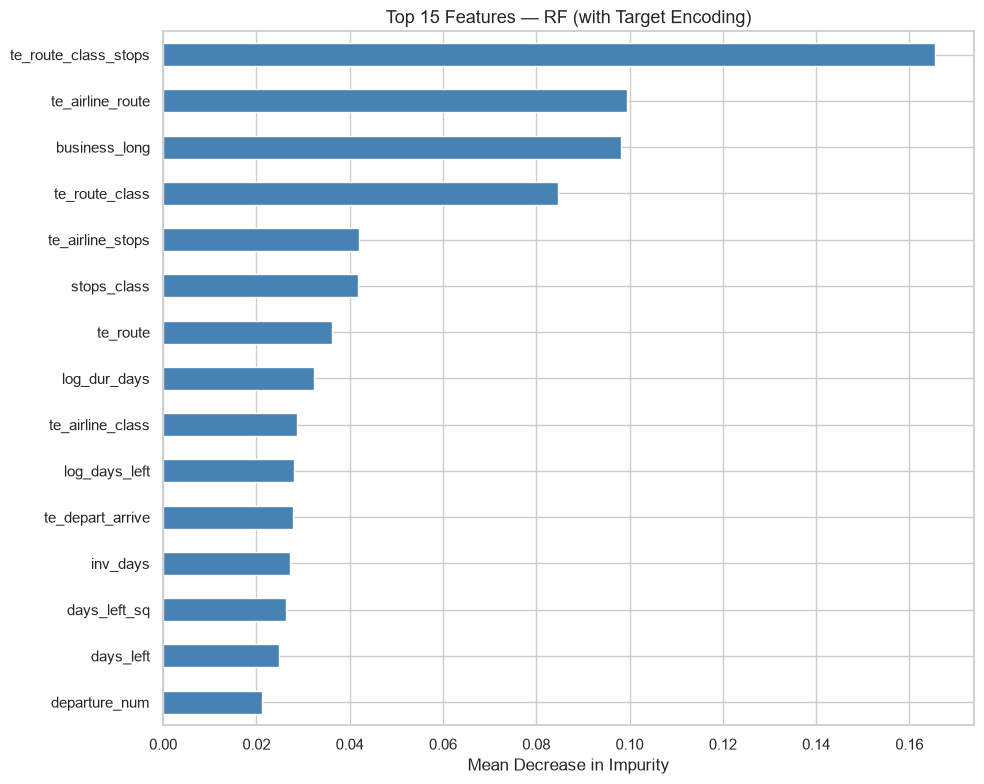


te_route_class_stops accounts for the most importance
— it captures the exact route × class × stop-count mean price, giving
  the model direct pricing signal per specific flight segment.


In [37]:
t0 = time.time()
rf_best = RandomForestRegressor(
    n_estimators     = BEST_N,
    max_features     = BEST_MF,
    min_samples_leaf = BEST_MSL,
    max_samples      = BEST_MS,
    random_state     = SEED,
    n_jobs           = -1
)
rf_best.fit(X_tr, y_tr)
p_best = np.maximum(rf_best.predict(X_val), 0)
print(f"Training time: {time.time()-t0:.1f}s")
m_best = evaluate(y_val, p_best, "RF (with target encoding)")

# Feature importance
fi = pd.Series(rf_best.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("\nTop 15 feature importances:")
display(fi.head(15).round(4).to_frame("Importance"))

fig, ax = plt.subplots(figsize=(10, 8))
fi.head(15).plot(kind="barh", ax=ax, color="steelblue")
ax.invert_yaxis()
ax.set_title("Top 15 Features — RF (with Target Encoding)", fontsize=13)
ax.set_xlabel("Mean Decrease in Impurity")
plt.tight_layout(); plt.show()

print("\nte_route_class_stops accounts for the most importance")
print("— it captures the exact route × class × stop-count mean price, giving")
print("  the model direct pricing signal per specific flight segment.")

## 8. Proper Nested CV

In [38]:
print("5-Fold Nested CV (TE computed inside each fold — zero leakage):")

df_cv = df_raw[df_raw["price"]>0].copy().reset_index(drop=True)
df_cv = engineer_features(df_cv)   # no TE yet

kf_outer = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2s = []

for fold, (tr_idx, vl_idx) in enumerate(kf_outer.split(df_cv)):
    tr_fold = df_cv.iloc[tr_idx].copy()
    vl_fold = df_cv.iloc[vl_idx].copy()

    # Fit TE on train fold, apply to val fold (no leakage)
    g_mean = tr_fold["price"].mean()
    for col in TE_COLS:
        m = tr_fold.groupby(col)["price"].mean()
        tr_fold[f"te_{col}"] = tr_fold[col].map(m).fillna(g_mean)
        vl_fold[f"te_{col}"] = vl_fold[col].map(m).fillna(g_mean)

    # Ordinal encode per fold
    oe_fold = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    tr_fold[CAT_COLS] = oe_fold.fit_transform(tr_fold[CAT_COLS])
    vl_fold[CAT_COLS] = oe_fold.transform(vl_fold[CAT_COLS])

    Xtr_f = tr_fold[FEATURES]; ytr_f = tr_fold["price"]
    Xvl_f = vl_fold[FEATURES]; yvl_f = vl_fold["price"]

    rf_cv = RandomForestRegressor(n_estimators=BEST_N, max_features=BEST_MF,
                                  min_samples_leaf=BEST_MSL, max_samples=BEST_MS,
                                  random_state=SEED, n_jobs=-1)
    rf_cv.fit(Xtr_f, ytr_f)
    p_cv = np.maximum(rf_cv.predict(Xvl_f), 0)
    r2_cv = r2_score(yvl_f, p_cv)
    cv_r2s.append(r2_cv)
    print(f"  Fold {fold+1}: R²={r2_cv:.4f}")

print(f"\nMean CV R²: {np.mean(cv_r2s):.4f} ± {np.std(cv_r2s):.4f}")
print("(High std is expected: some folds get more extreme-price test examples)")

5-Fold Nested CV (TE computed inside each fold — zero leakage):
  Fold 1: R²=0.7955
  Fold 2: R²=0.6909
  Fold 3: R²=0.5596
  Fold 4: R²=0.7648
  Fold 5: R²=0.7788

Mean CV R²: 0.7179 ± 0.0869
(High std is expected: some folds get more extreme-price test examples)


## 9. Final Model — Retrain on Full Training Data

In [39]:
print("=" * 60)
print("FINAL MODEL — training on 100% of data for submission")
print("=" * 60)

# ── Step 1: Engineer features on full training set ────────────────────────────
df_final_raw = pd.read_csv(TRAIN_PATH)
df_final_raw = df_final_raw[df_final_raw["price"] > 0].copy().reset_index(drop=True)
df_final = engineer_features(df_final_raw)

# ── Step 2: OOF TE on full training set ──────────────────────────────────────
print("Computing OOF target encoding on full training set...")
df_final = oof_target_encode(df_final, TE_COLS, target_col="price", n_splits=5, seed=SEED)

# ── Step 3: Store FULL-SET TE means for test application ─────────────────────
# (OOF means are for training, full means are for test)
te_full_means = {}
df_te_base = engineer_features(df_final_raw)   # raw string columns for groupby
for col in TE_COLS:
    te_full_means[col] = df_te_base.groupby(col)["price"].mean().to_dict()
global_mean_full = df_final_raw["price"].mean()
print(f"Global mean price (fallback): ${global_mean_full:.2f}")

# ── Step 4: Ordinal encode full training set ──────────────────────────────────
oe_final = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
df_final[CAT_COLS] = oe_final.fit_transform(df_final[CAT_COLS])

X_final = df_final[FEATURES]
y_final = df_final["price"]

# ── Step 5: Fit final model ───────────────────────────────────────────────────
t0 = time.time()
final_rf = RandomForestRegressor(
    n_estimators     = BEST_N,
    max_features     = BEST_MF,
    min_samples_leaf = BEST_MSL,
    max_samples      = BEST_MS,
    random_state     = SEED,
    n_jobs           = -1
)
final_rf.fit(X_final, y_final)
print(f"Final model trained in {time.time()-t0:.1f}s on {len(X_final)} samples.")
print(f"  n_estimators     = {BEST_N}")
print(f"  max_features     = {BEST_MF}")
print(f"  min_samples_leaf = {BEST_MSL}")
print(f"  max_samples      = {BEST_MS}")

FINAL MODEL — training on 100% of data for submission
Computing OOF target encoding on full training set...
Global mean price (fallback): $280.65
Final model trained in 1.6s on 18051 samples.
  n_estimators     = 200
  max_features     = 0.3
  min_samples_leaf = 2
  max_samples      = 0.85


## 10. Generate Submission

In [40]:
# ── Load test set ─────────────────────────────────────────────────────────────
df_test = pd.read_csv(TEST_PATH)
print(f"Test shape: {df_test.shape}")

# ── Apply identical feature engineering ───────────────────────────────────────
df_test_eng = engineer_features(df_test)

# ── Apply target encoding using FULL TRAINING SET means ───────────────────────
# (NOT OOF — OOF is only for training rows)
for col in TE_COLS:
    df_test_eng[f"te_{col}"] = df_test_eng[col].map(te_full_means[col]).fillna(global_mean_full)
print("Target encoding applied to test set using full training set means.")

# ── Apply SAME ordinal encoder (fitted on training) ───────────────────────────
df_test_eng[CAT_COLS] = oe_final.transform(df_test_eng[CAT_COLS])

# ── Predict ───────────────────────────────────────────────────────────────────
X_test = df_test_eng[FEATURES]
test_preds = np.maximum(final_rf.predict(X_test), 0)

# ── Format submission ─────────────────────────────────────────────────────────
submission = pd.DataFrame({"id": df_test["id"], "price": test_preds.astype(int)})
print(f"\nSubmission shape: {submission.shape}  (expected 4521 × 2)")
print(submission.head(10))
print(f"\nPredicted price stats:")
print(submission["price"].describe().round(1))

submission.to_csv("Regression_Dataset/submission_rf_v2.csv", index=False)
print("\nSaved: submission_rf_v2.csv")

Test shape: (4520, 11)
Target encoding applied to test set using full training set means.

Submission shape: (4520, 2)  (expected 4521 × 2)
      id  price
0  18395     69
1  11771    158
2  22326    464
3  18332    142
4  11021    556
5   8614    220
6  17654    106
7  14898    155
8   8794    136
9  15325    199

Predicted price stats:
count    4520.0
mean      280.5
std       189.5
min        31.0
25%       159.0
50%       243.0
75%       348.0
max      2250.0
Name: price, dtype: float64

Saved: submission_rf_v2.csv
